# Bloxorz — trực quan hóa benchmark 4 thuật toán trên 20 map

**Mục tiêu:** so sánh thời gian, bộ nhớ, công sức tìm kiếm và chất lượng lời giải
của **BFS, DFS, UCS, A*** qua **7 biểu đồ** có thể dùng trong báo cáo.

Nguồn: [CSV benchmark](../benchmarks/benchmark_20_maps.csv) ·
[Schema v1.0.0](../docs/benchmark_csv_schema.md) · code solver được đo: `29f2323`.

**Phạm vi:** 80 quan sát = 20 map × 4 thuật toán × 1 lần chạy; giới hạn mỗi lượt
30 giây / 150.000 node. Notebook đọc dữ liệu đã đo, không chạy lại solver.
Các boxplot mô tả khác biệt **giữa map**, không phải sai số của các phép đo lặp.
Thời gian bao gồm `tracemalloc` và dựng heuristic A*; bộ nhớ là peak Python
allocations, không phải RSS. Tất cả hành động, kể cả `switch`, có chi phí 1.

Chọn kernel đã cài `visualization/requirements.txt`, rồi **Run All**.
Mỗi lần chạy sẽ cập nhật 7 cặp hình PNG/SVG trong `figures/`.

## 1. Đọc dữ liệu và kiểm chứng trước khi vẽ

Tách phần đọc dữ liệu và vẽ hình vào `benchmark_plots.py` để notebook tập trung
vào phân tích. Không tính trung bình bằng cách gộp tùy ý các run khác nhau.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

search_from = Path.cwd().resolve()
ROOT = next((p for p in (search_from, *search_from.parents)
             if (p / 'benchmarks/benchmark_20_maps.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ repository BloxorzSolver.')
sys.path.insert(0, str(ROOT / 'visualization'))
from benchmark_plots import (
    ALGORITHMS, MAPS, load_benchmark, summary_table, metric_matrix,
    paired_ratios, configure_style, save_figure,
    plot_runtime_heatmap, plot_runtime_distribution, plot_memory_distribution,
    plot_expanded_nodes, plot_solution_lengths, plot_nodes_vs_time, plot_relative_profile,
)

configure_style()
CSV_PATH = ROOT / 'benchmarks/benchmark_20_maps.csv'
FIGURES = ROOT / 'visualization/figures'
data = load_benchmark(CSV_PATH)
print(f'{len(data)} dòng | {data.map_id.nunique()} map | {data.algorithm.nunique()} thuật toán')
print(f'Run ID: {data.run_id.iloc[0]}')
print(f'CSV SHA-256: {hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()}')
print(f'Solver commit: {data.git_commit.iloc[0]}')
print(f'Môi trường đo: Python {data.python_version.iloc[0]} / {data.platform.iloc[0]}')
print(f'Thời điểm đo (UTC): {data.started_at_utc.min()} → {data.started_at_utc.max()}')

80 dòng | 20 map | 4 thuật toán
Run ID: 0fdb2371-11ac-4f06-a861-c168dd3e092b
CSV SHA-256: 87de9856378ec831d3b77b6f5a16bfb241de0cbad701853035b45463b88936ac
Solver commit: 29f232303ee2dd234edfcc6580aa3c415b5428c6
Môi trường đo: Python 3.14.7 / macOS-26.6.2-arm64-arm-64bit-Mach-O
Thời điểm đo (UTC): 2026-10-22 10:38:12+00:00 → 2026-10-22 10:38:46+00:00


In [2]:
lengths = metric_matrix(data, 'solution_length')
assert lengths.BFS.equals(lengths.UCS)
assert lengths.BFS.equals(lengths['A*'])
assert (lengths.DFS >= lengths.BFS).all()
assert len(data) == 80 and data.solution_valid.all()

audit = pd.DataFrame({
    'Kiểm tra': ['Đủ map × thuật toán', 'Không trùng khóa', 'Cờ replay hợp lệ trong CSV',
                'BFS = UCS = A* về số bước', 'Chi phí bằng số hành động'],
    'Kết quả': ['80 / 80', '80 khóa duy nhất', '80 / 80', '20 / 20 map', '80 / 80'],
})
display(audit)
summary = summary_table(data)
display(summary.round(4))

,Kiểm tra,Kết quả
0,Đủ map × thuật toán,80 / 80
1,Không trùng khóa,80 khóa duy nhất
2,Cờ replay hợp lệ trong CSV,80 / 80
3,BFS = UCS = A* về số bước,20 / 20 map
4,Chi phí bằng số hành động,80 / 80


,solved_maps,median_time_s,max_time_s,median_memory_mib,max_memory_mib,median_expanded_nodes,median_solution_moves
algorithm,,,,,,,
BFS,20,0.0574,1.8663,0.1561,3.1142,301.0,45.0
DFS,20,0.0419,0.4126,0.1136,1.6272,207.5,90.5
UCS,20,0.0615,1.9442,0.1329,2.9510,301.0,45.0
A*,20,0.9438,1.8541,2.0428,3.9182,110.0,45.0


Bảng trên dùng **median trên 20 map** cho từng thuật toán; `max_*` là giá trị
lớn nhất quan sát được trong bộ map này. `median_solution_moves` giữa thuật toán
không thay thế so sánh **trên cùng một map** ở biểu đồ 5 và 7.

Loader đã kiểm tra schema, khóa, số lượng, giới hạn, kiểu dữ liệu và chuỗi hành
động. Cờ replay lấy từ CSV; lần replay bằng luật chơi đã được kiểm tra khi tạo dữ liệu.

## 2. Biểu đồ 1 — thời gian trên từng map

Heatmap giữ đủ 80 quan sát để thấy map nào tốn thời gian với thuật toán nào. Màu dùng thang log vì thời gian chênh lệch nhiều; số trong ô vẫn là **giây**. So sánh các ô trong cùng một hàng trước khi so sánh tổng thể.

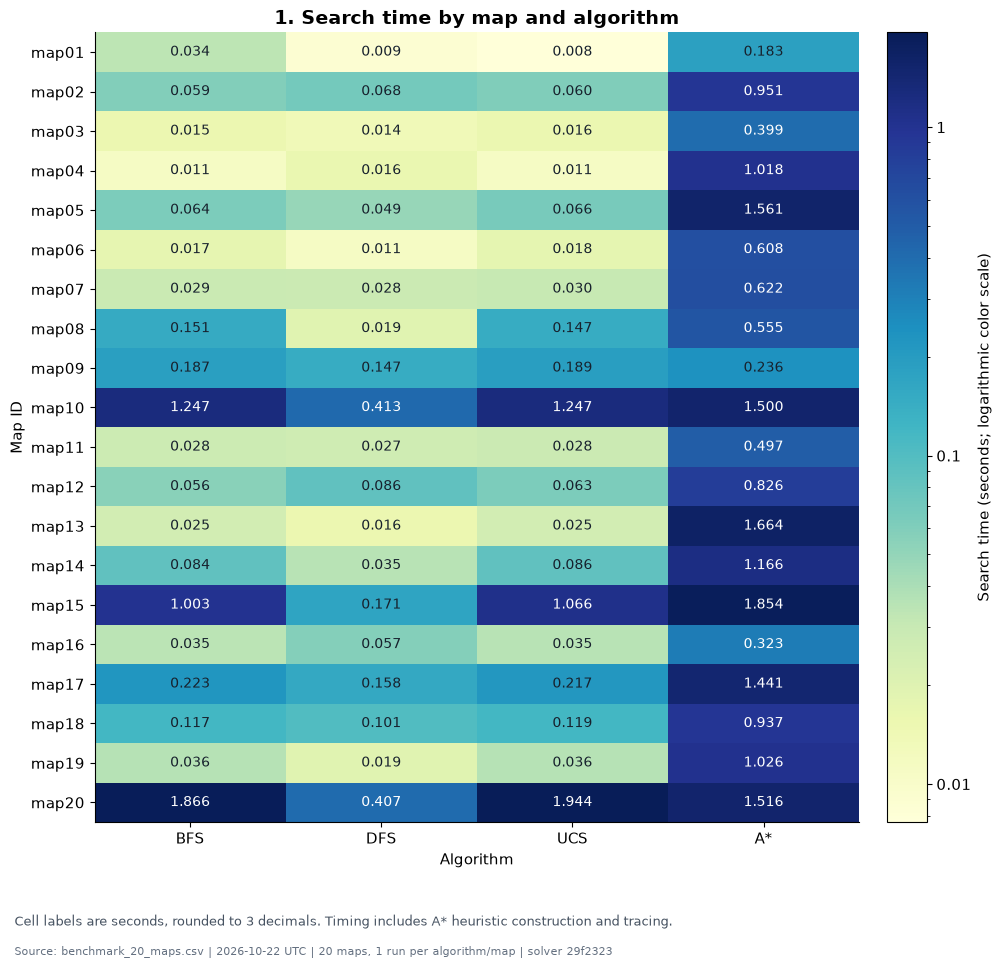

In [3]:
fig = plot_runtime_heatmap(data)
save_figure(fig, FIGURES, '01_runtime_heatmap')
display(fig)
plt.close(fig)

## 3. Biểu đồ 2 — phân bố thời gian giữa các map

Boxplot thể hiện Q1, median, Q3; whisker theo quy tắc 1,5 IQR. Mỗi điểm là một map, nên không ẩn những quan sát nằm ngoài whisker. Nhãn bên hộp là median (giây). Đây là độ phân tán **giữa 20 bài toán**, không phải khoảng tin cậy.

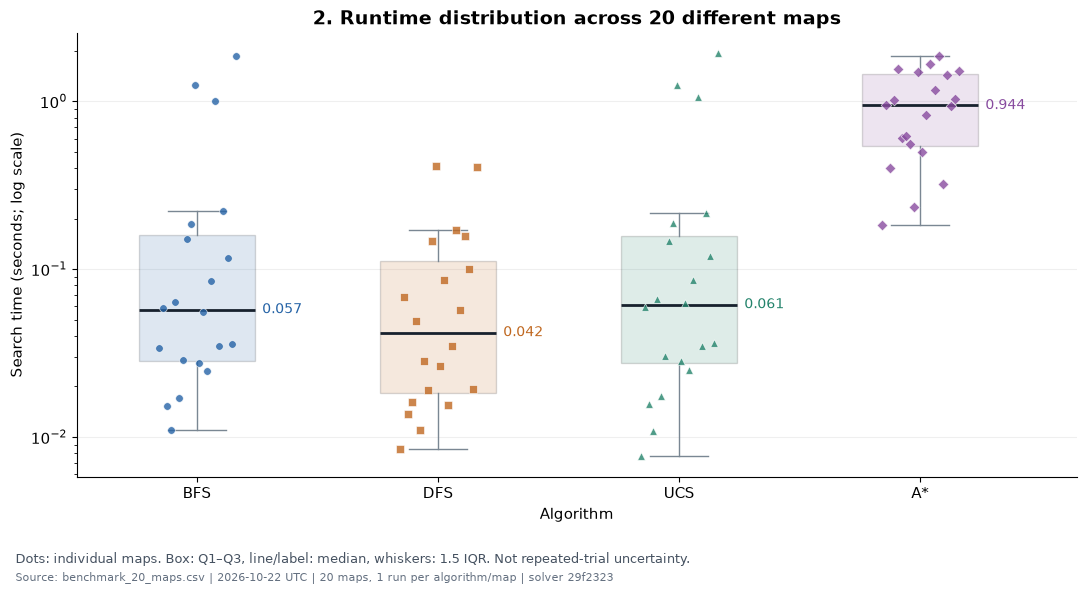

In [4]:
fig = plot_runtime_distribution(data)
save_figure(fig, FIGURES, '02_runtime_distribution')
display(fig)
plt.close(fig)

## 4. Biểu đồ 3 — bộ nhớ Python đỉnh

Đổi byte sang **MiB = byte / 1.048.576** để đọc thuận tiện. Vẽ tất cả điểm và hộp phân bố trên thang log. Các vùng cấp phát khi dựng bảng heuristic A* được tính; số liệu này không đo toàn bộ RAM của tiến trình.

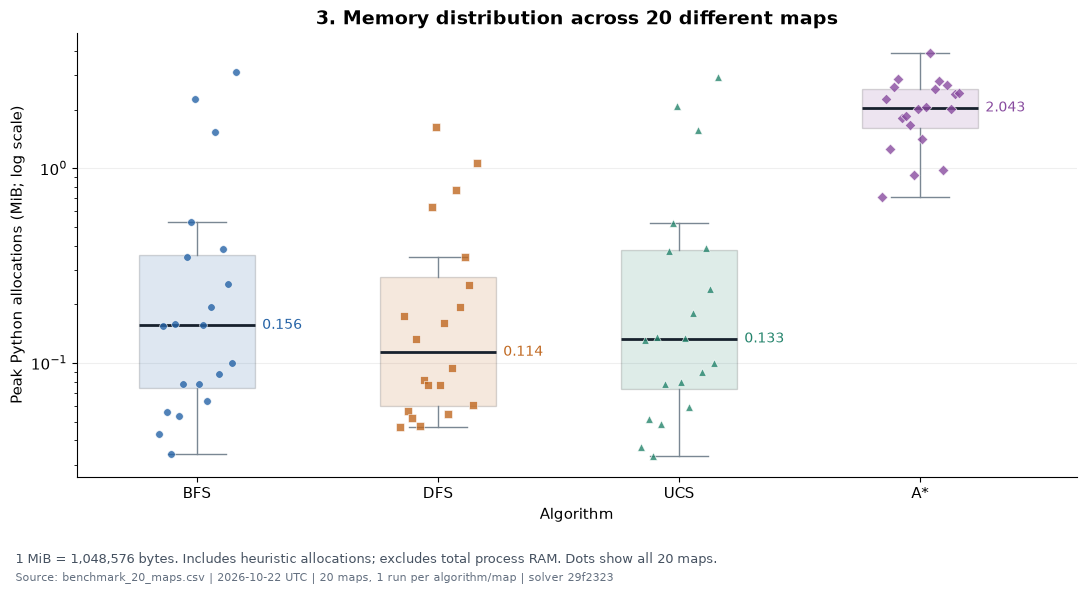

In [5]:
fig = plot_memory_distribution(data)
save_figure(fig, FIGURES, '03_memory_distribution')
display(fig)
plt.close(fig)

## 5. Biểu đồ 4 — số node thực sự mở rộng

Đồ thị theo map cho thấy công sức tìm kiếm. BFS/UCS được gộp thành một đường **chỉ sau khi kiểm tra hai chuỗi số liệu bằng nhau**. Trục Y là log; các map là hạng mục, không phải chuỗi thời gian. A* không cộng node tiền xử lý vào metric này.

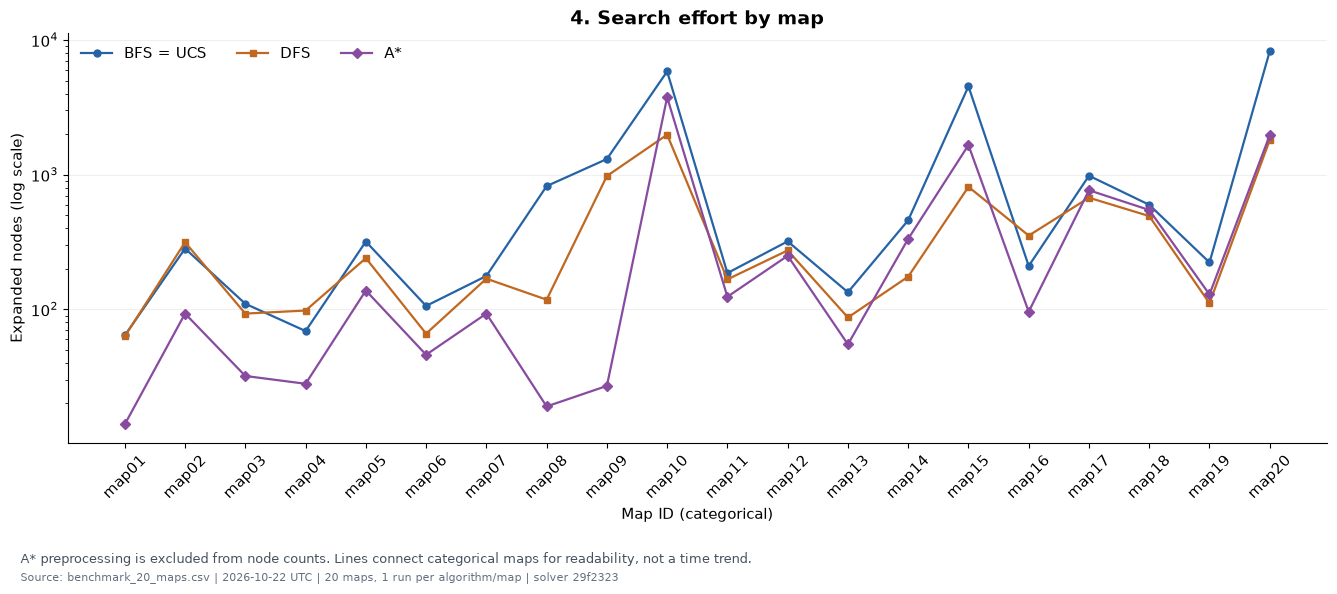

In [6]:
fig = plot_expanded_nodes(data)
save_figure(fig, FIGURES, '04_expanded_nodes')
display(fig)
plt.close(fig)

## 6. Biểu đồ 5 — chất lượng đường đi bằng dumbbell

Mỗi hàng nối độ dài của BFS/UCS/A* với DFS trên **cùng map**. Nhãn ghi số bước DFS và hệ số so với BFS. Thang log giúp thấy cả đường đi ngắn lẫn dài hàng nghìn bước. Lời giải DFS nhanh hơn, nếu có, không đồng nghĩa đường đi tốt hơn.

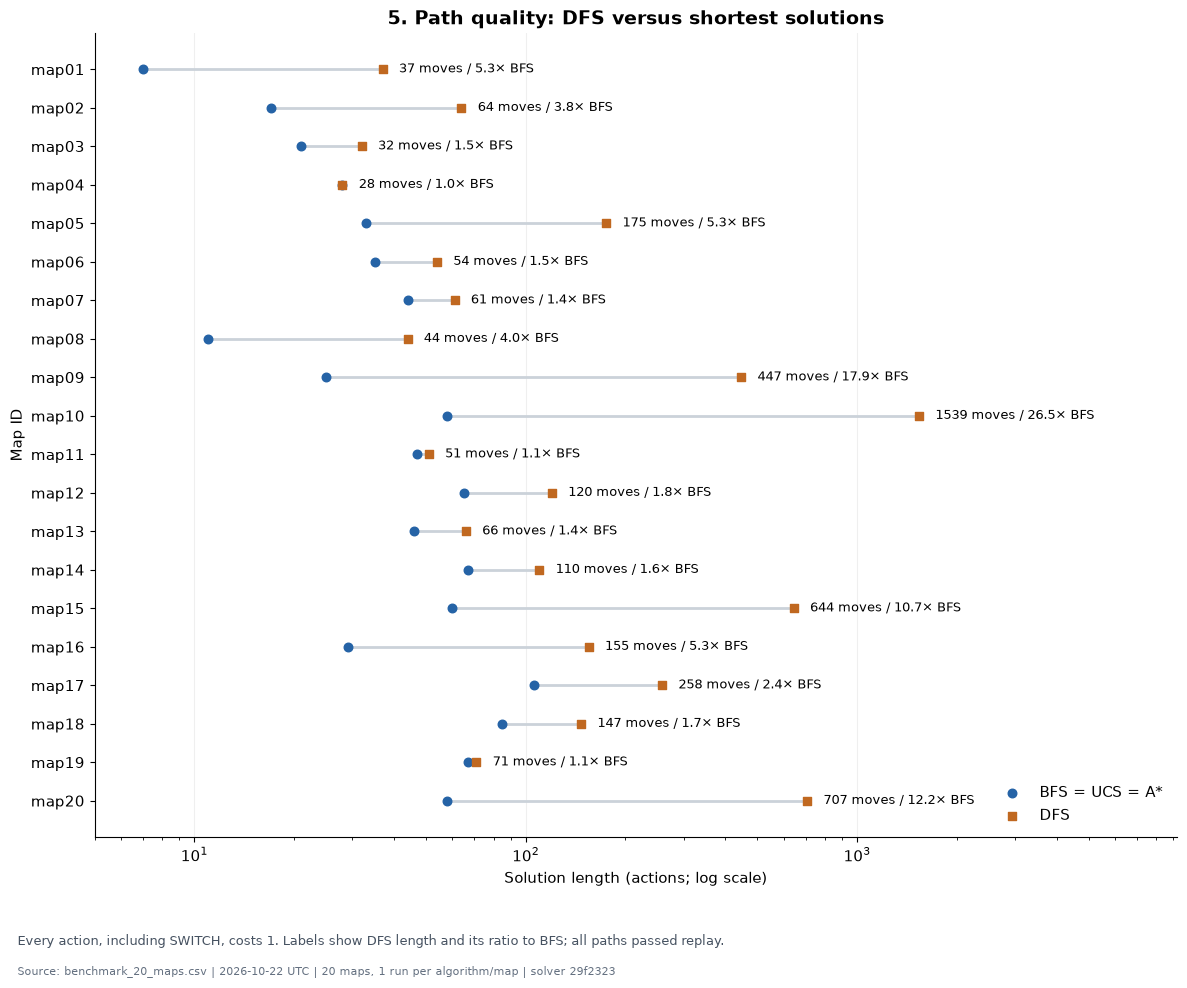

In [7]:
fig = plot_solution_lengths(data)
save_figure(fig, FIGURES, '05_solution_lengths')
display(fig)
plt.close(fig)

## 7. Biểu đồ 6 — quan hệ số node và thời gian

Scatter log–log dùng màu và marker để nhận diện 4 thuật toán. Một điểm là một cặp map–thuật toán; nhãn đánh dấu map chậm nhất của từng thuật toán trong lần đo này. Không fit hồi quy hoặc suy ra nhân quả từ 80 điểm.

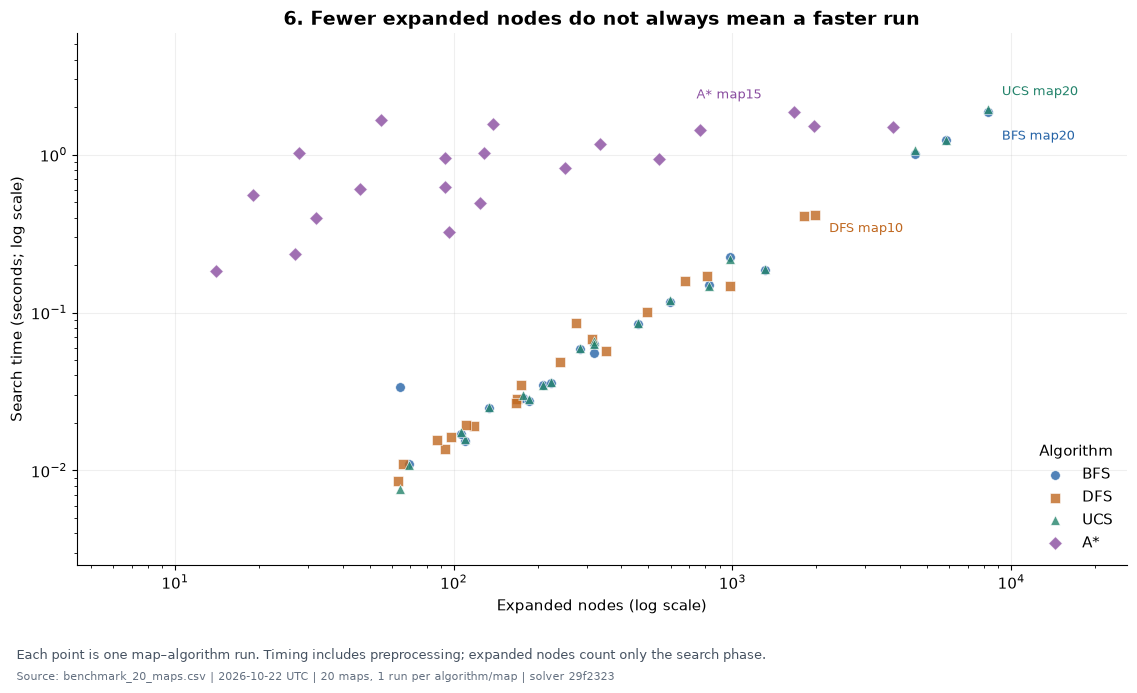

In [8]:
fig = plot_nodes_vs_time(data)
save_figure(fig, FIGURES, '06_nodes_vs_time')
display(fig)
plt.close(fig)

## 8. Biểu đồ 7 — tỷ lệ ghép theo map so với BFS

Với mỗi map, tính **metric(thuật toán) / metric(BFS)**, rồi lấy median của 20 tỷ lệ. Cả bốn metric đều càng thấp càng tốt: 1× ngang BFS, <1× thấp hơn, >1× cao hơn. Màu là log2 của tỷ lệ, cân bằng quanh 1×. Đây không phải tỷ lệ của hai median và không phải điểm xếp hạng tổng hợp.

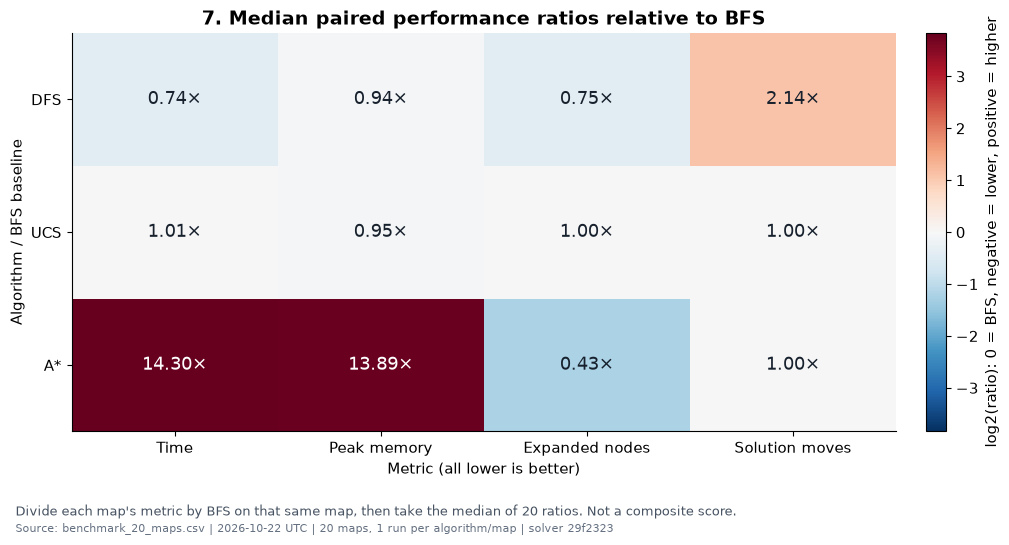

In [9]:
fig = plot_relative_profile(data)
save_figure(fig, FIGURES, '07_relative_to_bfs')
display(fig)
plt.close(fig)

## 9. Kết luận được tính từ dữ liệu

Các kết luận dưới đây được tính lại khi chạy notebook. Chúng chỉ mô tả bộ CSV
này; không khẳng định thuật toán tốt nhất cho mọi map hoặc độ ổn định qua nhiều lần đo.

In [10]:
time_ratios = paired_ratios(data, 'search_time_s')
node_ratios = paired_ratios(data, 'expanded_nodes')
memory_ratios = paired_ratios(data, 'peak_memory_bytes')
move_ratios = paired_ratios(data, 'solution_length')
worst_dfs_map = move_ratios.DFS.idxmax()
astar_faster = int((time_ratios['A*'] < 1).sum())
astar_fewer = int((node_ratios['A*'] < 1).sum())
dfs_same_length = int((move_ratios.DFS == 1).sum())

display(Markdown(f"""
- **Lời giải:** 80/80 cờ replay hợp lệ; BFS, UCS và A* có cùng số bước trên 20/20 map.
- **BFS và UCS:** cùng số node mở rộng trên cả 20 map. Chênh lệch thời gian của
  một lần đo không đủ để kết luận thuật toán nào luôn nhanh hơn.
- **A*:** mở rộng ít node hơn BFS trên **{astar_fewer}/20 map**, nhưng chỉ nhanh hơn
  BFS trên **{astar_faster}/20 map** trong lần đo này. Median tỷ lệ theo map:
  thời gian **{time_ratios['A*'].median():.2f}×**, node **{node_ratios['A*'].median():.2f}×**,
  bộ nhớ **{memory_ratios['A*'].median():.2f}×** BFS. Chi phí dựng heuristic nằm trong
  thời gian/bộ nhớ nhưng không nằm trong số node tìm kiếm; đó là một yếu tố cần
  xét khi diễn giải, chưa phải phép đo tách riêng từng giai đoạn.
- **DFS:** đường đi ngang BFS trên **{dfs_same_length}/20 map**. Trường hợp dài hơn
  nhiều nhất là **{worst_dfs_map}**: {int(lengths.loc[worst_dfs_map, 'DFS'])} so với
  {int(lengths.loc[worst_dfs_map, 'BFS'])} bước, tức **{move_ratios.loc[worst_dfs_map, 'DFS']:.2f}×**.
- **Giới hạn:** mỗi cặp chỉ đo một lần; chưa có warm-up, phân phối phép đo lặp
  hoặc khoảng tin cậy. Muốn đánh giá hiệu năng chắc hơn cần nhiều trial cùng điều kiện
  và có thể đo riêng thời gian chuẩn bị heuristic / thời gian tìm kiếm.
"""))

png_files = sorted(FIGURES.glob('[0-9][0-9]_*.png'))
svg_files = sorted(FIGURES.glob('[0-9][0-9]_*.svg'))
assert len(png_files) == len(svg_files) == 7
print('Đã xuất 7 PNG + 7 SVG trong visualization/figures/.')


- **Lời giải:** 80/80 cờ replay hợp lệ; BFS, UCS và A* có cùng số bước trên 20/20 map.
- **BFS và UCS:** cùng số node mở rộng trên cả 20 map. Chênh lệch thời gian của
  một lần đo không đủ để kết luận thuật toán nào luôn nhanh hơn.
- **A*:** mở rộng ít node hơn BFS trên **20/20 map**, nhưng chỉ nhanh hơn
  BFS trên **1/20 map** trong lần đo này. Median tỷ lệ theo map:
  thời gian **14.30×**, node **0.43×**,
  bộ nhớ **13.89×** BFS. Chi phí dựng heuristic nằm trong
  thời gian/bộ nhớ nhưng không nằm trong số node tìm kiếm; đó là một yếu tố cần
  xét khi diễn giải, chưa phải phép đo tách riêng từng giai đoạn.
- **DFS:** đường đi ngang BFS trên **1/20 map**. Trường hợp dài hơn
  nhiều nhất là **map10**: 1539 so với
  58 bước, tức **26.53×**.
- **Giới hạn:** mỗi cặp chỉ đo một lần; chưa có warm-up, phân phối phép đo lặp
  hoặc khoảng tin cậy. Muốn đánh giá hiệu năng chắc hơn cần nhiều trial cùng điều kiện
  và có thể đo riêng thời gian chuẩn bị heuristic / thời gian tìm kiếm.


Đã xuất 7 PNG + 7 SVG trong visualization/figures/.
